# LDO projektovanje gm/ID metodologijom — proračun $A_{uk}$

Notebook koristi četiri LUT funkcije iz `gmid_toolbox.py` i tačno
zadate naponske relacije. Slobodne naponske promenljive $V_S$ i
$V_{G6}$ numerički se određuju iz izabranih vrednosti
$(g_m/I_D)_{n1}$ i $(g_m/I_D)_{p2}$.

Za PMOS se LUT-u prosleđuju pozitivne magnitude $V_{SG}$ i $V_{SD}$.
Ekstrapolacija van karakterisane MAT baze nije dozvoljena.

U relaciji za $V_{D5}$ oznaka `gmIdD2` tumači se kao stvarni
`gmIDn2`, jer se taj odnos zatim dobija iz terminalnih napona n2.
Zbog toga je jednačina implicitna i rešava se do samosaglasnosti.


In [8]:
from dataclasses import asdict, dataclass
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq

from gmid_toolbox import GMIDToolbox, LUTError

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.max_columns", 100)


## 1. Fiksni projektni parametri

Ovo je jedino mesto koje treba menjati za drugi $V_{DD}$, $V_{OUT}$,
dužine kanala ili fiksni $(g_m/I_D)_{pass}$. Parametar `VSD_PASS`
ostavljen je eksplicitno na 0.10 V, kao u zadatoj relaciji za $V_{G0}$;
ne izjednačava se automatski sa `VDD - VOUT`.


In [9]:
# Naponi
VDD = 1.20
VREF = 0.50
VOUT = 1.00
VSD_PASS = 0.10

# Fiksni gm/ID i dužine
GMID_PASS = 10.0       # 1/V
LPASS_NM = 65.0        # nm
LD_NM = 130.0          # nm

# Traženi grafik
GMID_N1_SWEEP = np.linspace(5.0, 25.0, 41)
GMID_P2_LINES = [13, 14, 15, 16, 17, 18]

# Body bias po zadatku
VSB_N = 0.0
VBS_P = 0.0

# Numeričke postavke
ROOT_EPS_V = 1e-7
ROOT_TOL_V = 1e-9

DATA_DIR = Path.cwd()
tb = GMIDToolbox(
    nmos_mat=DATA_DIR / "65nch.mat",
    pmos_mat=DATA_DIR / "65pch.mat",
    nmos_variable="nch",
    pmos_variable="pch",
)

LUT1, LUT2, LUT3, LUT4 = tb.LUT1, tb.LUT2, tb.LUT3, tb.LUT4
print(tb.info())


{'nmos': {'kind': 'nmos', 'L_um': (0.06, 1.0), 'VGS_or_VSG_V': (0.0, 1.2), 'VDS_or_VSD_V': (0.0, 1.2), 'VSB_or_VBS_V': (0.0, 0.8)}, 'pmos': {'kind': 'pmos', 'L_um': (0.06, 1.0), 'VGS_or_VSG_V': (0.0, 1.2), 'VDS_or_VSD_V': (0.0, 1.2), 'VSB_or_VBS_V': (0.0, 0.8)}}


## 2. Relacije koje se koriste

$$
V_{G0}
=
V_{DD}
-
\mathrm{LUT1}
\left(
\mathrm{pch},
\left(\frac{g_m}{I_D}\right)_{\mathrm{pass}},
0.1,
0,
L_{\mathrm{pass}}
\right)
$$

$$
V_{G6}
=
V_{DD}
-
\mathrm{LUT1}
\left(
\mathrm{pch},
\left(\frac{g_m}{I_D}\right)_{p2},
V_{DD}-V_{G0},
0,
L_d
\right)
$$

$$
\left(\frac{g_m}{I_D}\right)_{n1}
=
\mathrm{LUT3}
\left(
\mathrm{nch},
0.5-V_S,
V_{G6}-V_S,
0,
L_d
\right)
$$

Kada je $V_S$ rešen, LUT2 se poziva sa `preferred_vds=VG6-VS` kako bi zadržao isti presek ako inverzni LUT ima više rešenja:

$$
V_{D3}
=
\mathrm{LUT2}
\left(
\mathrm{nch},
\left(\frac{g_m}{I_D}\right)_{n1},
0.5-V_S,
0,
L_d
\right)
$$

Za $V_{D5}$ rešava se implicitna relacija

$$
V_{D5}
=
V_{DD}
-
\mathrm{LUT1}
\left(
\mathrm{nch},
\left(\frac{g_m}{I_D}\right)_{n2},
V_{DD}-V_{D3},
0,
L_d
\right)
$$

gde je

$$
\left(\frac{g_m}{I_D}\right)_{n2}
=
\mathrm{LUT3}
\left(
\mathrm{nch},
V_{D5},
V_{G0},
0,
L_d
\right)
$$

In [10]:
@dataclass(frozen=True)
class LDOResult:
    gmid_n1_target: float
    gmid_p2_target: float
    VG0: float
    VG6: float
    VS: float
    VDS3: float
    VD3: float
    VD5: float
    gmid_pass: float
    gmid_n1: float
    gmid_p1: float
    gmid_n2: float
    gmid_p2: float
    gdsid_pass: float
    gdsid_n1: float
    gdsid_p1: float
    gdsid_n2: float
    gdsid_p2: float
    Ap: float
    A1: float
    A2: float
    Auk: float
    Auk_dB: float


def _all_roots(func, low, high, *, n_scan=121):
    '''Svi preseci u intervalu, bez ekstrapolacije preko nevalidnih tačaka.'''
    xs = np.linspace(float(low), float(high), int(n_scan))
    samples = []
    for x in xs:
        try:
            y = float(func(float(x)))
        except (LUTError, ValueError, FloatingPointError):
            continue
        if np.isfinite(y):
            samples.append((float(x), y))

    roots = []
    for x, y in samples:
        if abs(y) <= 1e-10:
            roots.append(x)

    for (x0, y0), (x1, y1) in zip(samples[:-1], samples[1:]):
        if y0 * y1 < 0:
            roots.append(float(brentq(func, x0, x1, xtol=ROOT_TOL_V)))

    if not roots:
        return []
    return sorted(set(np.round(roots, 12)))


def solve_vs(gmid_n1_target, VG6):
    '''Rešava LUT3(nch, VREF-VS, VG6-VS, 0, Ld) = ciljni gm/ID.'''
    info = tb.info()["nmos"]
    vgs_min, vgs_max = info["VGS_or_VSG_V"]
    vds_min, vds_max = info["VDS_or_VSD_V"]

    low = max(VREF - vgs_max, VG6 - vds_max) + ROOT_EPS_V
    high = min(VREF - vgs_min, VG6 - vds_min) - ROOT_EPS_V
    if low >= high:
        raise LUTError("Nema VS intervala koji ostavlja VGS i VDS u LUT opsegu.")

    def equation(VS):
        return (
            LUT3("nch", VREF - VS, VG6 - VS, VSB_N, LD_NM)
            - float(gmid_n1_target)
        )

    # U ovoj bazi je duž ove putanje funkcija monotona, pa je ovo brza grana.
    try:
        f_low, f_high = equation(low), equation(high)
        if f_low == 0:
            return float(low)
        if f_high == 0:
            return float(high)
        if f_low * f_high < 0:
            return float(brentq(equation, low, high, xtol=ROOT_TOL_V))
    except (LUTError, ValueError, FloatingPointError):
        pass

    roots = _all_roots(equation, low, high)
    if not roots:
        raise LUTError(
            f"gm/ID_n1={gmid_n1_target:g} 1/V nije ostvariv za VG6={VG6:.5f} V."
        )
    return float(min(roots, key=abs))


def solve_vd5(VD3, VG0):
    '''Rešava implicitnu VD5 relaciju sa gmIDn2 do samosaglasnosti.'''
    def vd5_map(VD5):
        gmid_n2 = LUT3("nch", VD5, VG0, VSB_N, LD_NM)
        return VDD - LUT1("nch", gmid_n2, VDD - VD3, VSB_N, LD_NM)

    # Prigušena fiksna tačka je ovde mnogo brža od punog scan-a.
    vd5 = 0.5 * VDD
    for _ in range(40):
        mapped = float(vd5_map(vd5))
        if abs(mapped - vd5) <= ROOT_TOL_V:
            return mapped
        vd5 = 0.5 * vd5 + 0.5 * mapped

    info = tb.info()["nmos"]
    vgs_min, vgs_max = info["VGS_or_VSG_V"]
    low = max(vgs_min, 0.0) + ROOT_EPS_V
    high = min(vgs_max, VDD) - ROOT_EPS_V
    equation = lambda value: value - vd5_map(value)
    roots = _all_roots(equation, low, high, n_scan=201)
    if not roots:
        raise LUTError("Implicitna jednačina za VD5 nema rešenje u LUT opsegu.")
    return float(min(roots, key=lambda value: abs(value - vd5)))


# Pass tranzistor je fiksan za ceo sweep.
VSG_PASS = LUT1("pch", GMID_PASS, VSD_PASS, VBS_P, LPASS_NM)
VG0_FIXED = VDD - VSG_PASS
GMID_PASS_ACTUAL = LUT3("pch", VSG_PASS, VSD_PASS, VBS_P, LPASS_NM)
GDSID_PASS_FIXED = LUT4("pch", VSG_PASS, VSD_PASS, VBS_P, LPASS_NM)
AP_FIXED = GMID_PASS_ACTUAL / (1.0 / VOUT + GDSID_PASS_FIXED)


@lru_cache(maxsize=None)
def solve_vg6(gmid_p2_target):
    '''VG6 zavisi samo od izabrane linije gm/ID_p2, pa se kešira.'''
    return VDD - LUT1(
        "pch", float(gmid_p2_target), VDD - VG0_FIXED, VBS_P, LD_NM
    )


def evaluate_ldo(gmid_n1_target, gmid_p2_target):
    '''Kompletna evaluacija jedne tačke sa svim zadatim LUT relacijama.'''
    VG0 = VG0_FIXED
    VG6 = solve_vg6(float(gmid_p2_target))
    VS = solve_vs(gmid_n1_target, VG6)

    # Ista grana LUT2 rešenja koja je već definisana jednačinom za n1.
    expected_vds_n1 = VG6 - VS
    VDS3 = LUT2(
        "nch",
        gmid_n1_target,
        VREF - VS,
        VSB_N,
        LD_NM,
        preferred_vds=expected_vds_n1,
        n_scan=161,
        relative_tolerance=1e-5,
    )
    # LUT2 vraća VDS3, dok je apsolutni napon drain čvora VD3=VS+VDS3.
    VD3 = VS + VDS3
    VD5 = solve_vd5(VD3, VG0)

    # Direktni LUT3/LUT4 pozivi, tačno u zadatim radnim tačkama.
    gmid_n1 = LUT3("nch", VREF - VS, VG6 - VS, VSB_N, LD_NM)
    gdsid_n1 = LUT4("nch", VREF - VS, VG6 - VS, VSB_N, LD_NM)

    gmid_p1 = LUT3("pch", VDD - VG6, VG6 - VS, VBS_P, LD_NM)
    gdsid_p1 = LUT4("pch", VDD - VG6, VG6 - VS, VBS_P, LD_NM)

    gmid_n2 = LUT3("nch", VD5, VG0, VSB_N, LD_NM)
    gdsid_n2 = LUT4("nch", VD5, VG0, VSB_N, LD_NM)

    gmid_p2 = LUT3("pch", VDD - VG6, VDD - VG0, VBS_P, LD_NM)
    gdsid_p2 = LUT4("pch", VDD - VG6, VDD - VG0, VBS_P, LD_NM)

    Ap = AP_FIXED
    A1 = gmid_n1 / (gdsid_n1 + gdsid_p1)
    A2 = gmid_p2 / (gdsid_n2 + gdsid_p2)
    Auk = Ap * A1 * A2

    return LDOResult(
        gmid_n1_target=float(gmid_n1_target),
        gmid_p2_target=float(gmid_p2_target),
        VG0=VG0,
        VG6=VG6,
        VS=VS,
        VDS3=VDS3,
        VD3=VD3,
        VD5=VD5,
        gmid_pass=GMID_PASS_ACTUAL,
        gmid_n1=gmid_n1,
        gmid_p1=gmid_p1,
        gmid_n2=gmid_n2,
        gmid_p2=gmid_p2,
        gdsid_pass=GDSID_PASS_FIXED,
        gdsid_n1=gdsid_n1,
        gdsid_p1=gdsid_p1,
        gdsid_n2=gdsid_n2,
        gdsid_p2=gdsid_p2,
        Ap=Ap,
        A1=A1,
        A2=A2,
        Auk=Auk,
        Auk_dB=20.0 * np.log10(abs(Auk)) if Auk != 0 else -np.inf,
    )


## 3. Provera jedne projektne tačke

Tabela prikazuje ciljne i stvarno interpolirane `gm/ID` vrednosti,
rešene napone, svaki stepen pojačanja i ukupno pojačanje.


In [11]:
point = evaluate_ldo(gmid_n1_target=15.0, gmid_p2_target=15.0)

point_table = pd.DataFrame(
    {"vrednost": asdict(point)}
)
display(point_table)

print(f"Ap  = {point.Ap:.6f} V/V")
print(f"A1  = {point.A1:.6f} V/V")
print(f"A2  = {point.A2:.6f} V/V")
print(f"Auk = {point.Auk:.6f} V/V = {point.Auk_dB:.3f} dB")


,vrednost
gmid_n1_target,15.000000
gmid_p2_target,15.000000
VG0,0.569913
VG6,0.670272
VS,0.003003
VDS3,0.667269
VD3,0.670272
VD5,0.599625
gmid_pass,10.000000
gmid_n1,15.000000


Ap  = 1.599975 V/V
A1  = 14.438268 V/V
A2  = 14.854085 V/V
Auk = 343.142281 V/V = 50.709 dB


## 4. Grafik $A_{uk}$ prema $(g_m/I_D)_{n1}$

X osa je tačno od 5 do 25 1/V. Svaka linija predstavlja jednu zadatu
vrednost $(g_m/I_D)_{p2}$: 13, 14, 15, 16, 17 i 18 1/V. Nevalidne LUT
tačke ostaju `NaN`, pa se ne crtaju lažne ekstrapolacije.


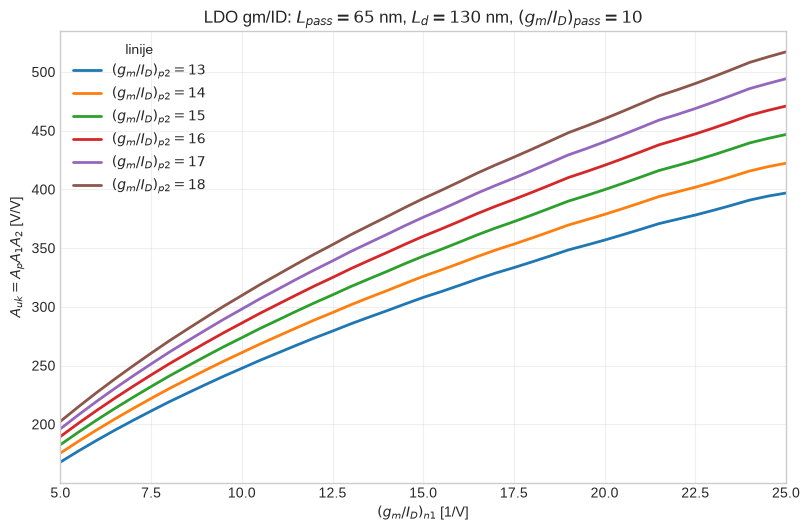

,gmIDp2 [1/V],broj validnih tačaka,ukupno tačaka
0,13,41,41
1,14,41,41
2,15,41,41
3,16,41,41
4,17,41,41
5,18,41,41


Grafik je sačuvan u: /home/paki/MIHAJLO/faks/aik/jupyter/projekat/LDO_Auk_vs_gmIDn1.png


In [12]:
curves = {}
rows = []
errors = []

for gmid_p2_target in GMID_P2_LINES:
    gain = []
    for gmid_n1_target in GMID_N1_SWEEP:
        try:
            result = evaluate_ldo(gmid_n1_target, gmid_p2_target)
            gain.append(result.Auk)
            rows.append(asdict(result))
        except (LUTError, ValueError, FloatingPointError) as exc:
            gain.append(np.nan)
            errors.append({
                "gmIDn1": gmid_n1_target,
                "gmIDp2": gmid_p2_target,
                "razlog": str(exc),
            })
    curves[gmid_p2_target] = np.asarray(gain, dtype=float)

results = pd.DataFrame(rows)
diagnostics = pd.DataFrame(errors)

fig, ax = plt.subplots(figsize=(8.2, 5.4))
for gmid_p2_target, gain in curves.items():
    ax.plot(
        GMID_N1_SWEEP,
        gain,
        linewidth=2.0,
        label=fr"$(g_m/I_D)_{{p2}}={gmid_p2_target:g}$",
    )

ax.set_xlim(5.0, 25.0)
ax.set_xlabel(r"$(g_m/I_D)_{n1}$ [1/V]")
ax.set_ylabel(r"$A_{uk}=A_p A_1 A_2$ [V/V]")
ax.set_title(
    fr"LDO gm/ID: $L_{{pass}}={LPASS_NM:g}$ nm, "
    fr"$L_d={LD_NM:g}$ nm, $(g_m/I_D)_{{pass}}={GMID_PASS:g}$"
)
ax.grid(True, alpha=0.30)
ax.legend(title="linije")
fig.tight_layout()

PLOT_PATH = DATA_DIR / "LDO_Auk_vs_gmIDn1.png"
fig.savefig(PLOT_PATH, dpi=180, bbox_inches="tight")
plt.show()

valid_counts = pd.DataFrame({
    "gmIDp2 [1/V]": list(curves),
    "broj validnih tačaka": [np.isfinite(y).sum() for y in curves.values()],
    "ukupno tačaka": len(GMID_N1_SWEEP),
})
display(valid_counts)
print(f"Grafik je sačuvan u: {PLOT_PATH}")


## 5. Maksimum svake krive i dijagnostika

Prva tabela daje najbolju tačku svake linije. Druga se prikazuje samo
ako postoji zahtev van LUT opsega ili numerički nerešiva tačka.


In [13]:
best_rows = []
for gmid_p2_target, gain in curves.items():
    finite = np.isfinite(gain)
    if not finite.any():
        best_rows.append({
            "gmIDp2 [1/V]": gmid_p2_target,
            "gmIDn1 @ max [1/V]": np.nan,
            "max Auk [V/V]": np.nan,
        })
        continue
    idx = int(np.nanargmax(gain))
    best_rows.append({
        "gmIDp2 [1/V]": gmid_p2_target,
        "gmIDn1 @ max [1/V]": GMID_N1_SWEEP[idx],
        "max Auk [V/V]": gain[idx],
    })

display(pd.DataFrame(best_rows).round(5))

if diagnostics.empty:
    print("Sve sweep tačke su validne u karakterisanoj LUT bazi.")
else:
    print(f"Broj odbačenih tačaka: {len(diagnostics)}")
    display(diagnostics.head(20))


,gmIDp2 [1/V],gmIDn1 @ max [1/V],max Auk [V/V]
0,13,25.0,396.90985
1,14,25.0,422.30125
2,15,25.0,446.74350
3,16,25.0,470.94691
4,17,25.0,494.21175
5,18,25.0,517.12147


Sve sweep tačke su validne u karakterisanoj LUT bazi.


## Napomena o interpretaciji

Korišćene su zadate aproksimacije:

$$
A_p
=
\frac{
\left(\dfrac{g_m}{I_D}\right)_{\mathrm{pass}}
}{
\dfrac{1}{V_{\mathrm{OUT}}}
+
\left(\dfrac{g_{ds}}{I_D}\right)_{\mathrm{pass}}
}
$$

$$
A_1
=
\frac{
\left(\dfrac{g_m}{I_D}\right)_{n1}
}{
\left(\dfrac{g_{ds}}{I_D}\right)_{n1}
+
\left(\dfrac{g_{ds}}{I_D}\right)_{p1}
}
$$

$$
A_2
=
\frac{
\left(\dfrac{g_m}{I_D}\right)_{p2}
}{
\left(\dfrac{g_{ds}}{I_D}\right)_{n2}
+
\left(\dfrac{g_{ds}}{I_D}\right)_{p2}
}
$$

$$
A_{\mathrm{uk}}=A_pA_1A_2
$$

Sabiranje `gds/ID` u imeniocu pretpostavlja jednake struje tranzistora koji dele dati izlazni čvor. Ako struje nisu jednake, potrebno je sabirati stvarne izlazne provodnosti:

$$
g_{ds,n}+g_{ds,p}
=
\left(\frac{g_{ds}}{I_D}\right)_n I_{D,n}
+
\left(\frac{g_{ds}}{I_D}\right)_p I_{D,p}.
$$

In [14]:
# ================================================================
# GM/ID SVIH TRANZISTORA ZA TRI ZADATA PROJEKTNA ULAZA
# ================================================================

GMID_N1_INPUT = 15.0
GMID_P2_INPUT = 15.0
GMID_PASS_INPUT = 10.0

# evaluate_ldo koristi globalnu pass radnu tačku. Privremeno je
# menjamo, računamo rezultat, a zatim vraćamo početne vrednosti.
_saved_pass_state = {
    "GMID_PASS": GMID_PASS,
    "VSG_PASS": VSG_PASS,
    "VG0_FIXED": VG0_FIXED,
    "GMID_PASS_ACTUAL": GMID_PASS_ACTUAL,
    "GDSID_PASS_FIXED": GDSID_PASS_FIXED,
    "AP_FIXED": AP_FIXED,
}

try:
    GMID_PASS = float(GMID_PASS_INPUT)
    VSG_PASS = LUT1(
        "pch", GMID_PASS, VSD_PASS, VBS_P, LPASS_NM
    )
    VG0_FIXED = VDD - VSG_PASS
    GMID_PASS_ACTUAL = LUT3(
        "pch", VSG_PASS, VSD_PASS, VBS_P, LPASS_NM
    )
    GDSID_PASS_FIXED = LUT4(
        "pch", VSG_PASS, VSD_PASS, VBS_P, LPASS_NM
    )
    AP_FIXED = (
        GMID_PASS_ACTUAL
        / (1.0 / VOUT + GDSID_PASS_FIXED)
    )

    # VG6 zavisi od VG0, zato stari cache više nije važeći.
    solve_vg6.cache_clear()

    gmid_point = evaluate_ldo(
        gmid_n1_target=GMID_N1_INPUT,
        gmid_p2_target=GMID_P2_INPUT,
    )
finally:
    GMID_PASS = _saved_pass_state["GMID_PASS"]
    VSG_PASS = _saved_pass_state["VSG_PASS"]
    VG0_FIXED = _saved_pass_state["VG0_FIXED"]
    GMID_PASS_ACTUAL = _saved_pass_state["GMID_PASS_ACTUAL"]
    GDSID_PASS_FIXED = _saved_pass_state["GDSID_PASS_FIXED"]
    AP_FIXED = _saved_pass_state["AP_FIXED"]
    solve_vg6.cache_clear()

gmid_table = pd.DataFrame([
    {
        "tranzistor": "pass",
        "zadati gm/ID [1/V]": GMID_PASS_INPUT,
        "izračunati gm/ID [1/V]": gmid_point.gmid_pass,
    },
    {
        "tranzistor": "n1",
        "zadati gm/ID [1/V]": GMID_N1_INPUT,
        "izračunati gm/ID [1/V]": gmid_point.gmid_n1,
    },
    {
        "tranzistor": "p1",
        "zadati gm/ID [1/V]": np.nan,
        "izračunati gm/ID [1/V]": gmid_point.gmid_p1,
    },
    {
        "tranzistor": "n2",
        "zadati gm/ID [1/V]": np.nan,
        "izračunati gm/ID [1/V]": gmid_point.gmid_n2,
    },
    {
        "tranzistor": "p2",
        "zadati gm/ID [1/V]": GMID_P2_INPUT,
        "izračunati gm/ID [1/V]": gmid_point.gmid_p2,
    },
]).set_index("tranzistor")

display(gmid_table.round(6))

node_check = pd.DataFrame({
    "napon [V]": {
        "VG0": gmid_point.VG0,
        "VG6": gmid_point.VG6,
        "VS": gmid_point.VS,
        "VDS3": gmid_point.VDS3,
        "VD3 = VS + VDS3": gmid_point.VD3,
        "VD5": gmid_point.VD5,
    }
})
display(node_check.round(6))


,zadati gm/ID [1/V],izračunati gm/ID [1/V]
tranzistor,,
pass,10.0,10.000000
n1,15.0,15.000000
p1,NaN,14.957667
n2,NaN,9.791840
p2,15.0,15.000000


,napon [V]
VG0,0.569913
VG6,0.670272
VS,0.003003
VDS3,0.667269
VD3 = VS + VDS3,0.670272
VD5,0.599625
